In [141]:
import rdkit
from rdkit import Chem
import numpy as np
import re
from rdkit.Chem.Draw import IPythonConsole
from rxnmapper import RXNMapper
from rdkit.Chem import AllChem

In [2]:
carbocat= Chem.MolFromSmiles('C[C+](C)C')
bromide = Chem.MolFromSmiles('[Br-]')
product = Chem.MolFromSmiles('CC(C)(Br)C')

In [3]:
match_p = Chem.MolFromSmarts('CC(C)C')

In [4]:
print(product.HasSubstructMatch(match_p))

True


In [153]:
canion = Chem.MolFromSmiles('C[CH-]C=O')
enolate = Chem.MolFromSmiles(r'C/C=C\[O-]')

aza_canion = Chem.MolFromSmiles(r'C[CH-]/C=[N+](C)\C')
azolate = Chem.MolFromSmiles(r'C/C=C/N(C)C')

ext_canion = Chem.MolFromSmiles(r'CC(=O)/C=C/[CH2-]')
ext_enolate = Chem.MolFromSmiles(r'C=C/C=C(C)\[O-]')

cat_and_brom = Chem.MolFromSmiles(r'C[C+](C)C.[Br-]')
tert_brom = Chem.MolFromSmiles('CC(C)(Br)C')

michael_r = Chem.MolFromSmiles(r'C=CC(C)=O.N')
michael_prod = Chem.MolFromSmiles(r'C/C([O-])=C/C[NH3+]')

allyl_cat_1 = Chem.MolFromSmiles(r'C/C(C)=C/[CH2+]')
allyl_cat_2 = Chem.MolFromSmiles(r'C=C[C+](C)C')

fc_sm= Chem.MolFromSmiles(r'c1ccccc1.O=[N+]=O')
fc_prod = Chem.MolFromSmiles(r'[O-][N+](=O)c1ccccc1.[H+]')

fc_sm_li = Chem.MolFromSmiles(r'[Li]c1ccccc1.O=[N+]=O')
fc_prod_li = Chem.MolFromSmiles(r'[O-][N+](=O)c1ccccc1.[Li+]')

alkene_bh3 = Chem.MolFromSmiles(r'C=C.B')
alkene_hb = Chem.MolFromSmiles(r'BCC')


params = Chem.SmilesParserParams()
params.removeHs = False

nitr_start_h_exp = Chem.MolFromSmiles(r'O=[N+]=O.[H]C1=CC=CC=C1', params)
nitr_int = Chem.MolFromSmiles(r'[H]C1([N+](=O)[O-])C=CC=C[CH+]1', params)

aldol = Chem.MolFromSmiles(r'C=C(C)[O-].O=Cc1ccccc1')
aldol_product = Chem.MolFromSmiles(r'CC(=O)CC([O-])c1ccccc1')
#Chem.Draw.MolToImage(product, highlightAtoms=hl)

cyano_sm = Chem.MolFromSmiles(r'CC(C)=O.[C-]#N')
cyano_prod = Chem.MolFromSmiles(r'CC(C)([O-])C#N')

bh4_red_sm = Chem.MolFromSmiles(r'O=C1CCCC1.[H][BH3-]', params)
bh4_red_prod = Chem.MolFromSmiles(r'B.[H]C1([O-])CCCC1', params)
#Chem.Draw.MolToImage(nitr_start_h_exp)

In [ ]:
class reducedBond:
    def __init__(self, bond):
        bond_pair = [bond.GetBeginAtom().GetAtomicNum(), bond.GetEndAtom().GetAtomicNum()]
        bond_pair.sort()
        self.pair = bond_pair
        self.bond_type = bond.GetBondTypeAsDouble()
    def __eq__(self, other):
        if isinstance(other, reducedBond):
            if self.pair == other.pair and self.bond_type == other.bond_type:
                return True
        return False

In [86]:
def find_chain(mol1, mol2):
    a_hl = []
    for atom in mol2.GetAtoms():
        atom_found = False
        for a in mol1.GetAtoms():
            if atom.GetFormalCharge() == a.GetFormalCharge() and atom.GetAtomicNum() == a.GetAtomicNum():
                atom_found = True
        if not atom_found:
            #print(atom.GetFormalCharge())
            #print(a.GetFormalCharge())
            #if atom.GetFormalCharge() > a.GetFormalCharge():
                #electron_source = a.GetIdx()
            a_hl.append(a.GetIdx())
    chain = set(a_hl)
    for bond in mol2.GetBonds():
        bond_found = False
        b1 = reducedBond(bond)
        for b in mol1.GetBonds():
            b2 = reducedBond(b)
            if b1 == b2:
                bond_found = True
        if not bond_found:
            chain.add(b.GetBeginAtomIdx())
            chain.add(b.GetEndAtomIdx())
    return chain

def find_source(mol1, mol2):
    a_hl = []
    for atom in mol2.GetAtoms():
        atom_found = False
        for a in mol1.GetAtoms():
            if atom.GetFormalCharge() == a.GetFormalCharge() and atom.GetAtomicNum() == a.GetAtomicNum():
                atom_found = True
        if not atom_found:
            if atom.GetFormalCharge() > a.GetFormalCharge():
                return a.GetIdx()

In [87]:
def get_atom_types(mol):
    atom_types={}
    for atom in mol.GetAtoms():
        atm_num = atom.GetAtomicNum()
        if atm_num in atom_types.keys():
            atom_types[atm_num].append(atom.GetIdx())
        else:
            atom_types[atm_num] = [atom.GetIdx()]
    return atom_types

def get_neighbour_atoms(mol, atom_types):
    neighbour_list = {}
    unique_atoms = {}
    for atm_num, atm_indices in atom_types.items():
        if len(atm_indices)==1:
            unique_atoms[atm_num]=atm_indices[0]
            continue
        neighbour_list[atm_num]={}
        for idx in atm_indices:
            nbrs=[]
            for nbr in mol.GetAtomWithIdx(idx).GetNeighbors():
                nbrs.append(nbr.GetAtomicNum())
            neighbour_list[atm_num][idx]=nbrs
    return neighbour_list, unique_atoms

In [89]:
def find_charge_diff(mol1, mol2, mapping):
    a_lost = []
    a_gain = []
    for atom1, atom2 in mapping.items():
        if mol2.GetAtomWithIdx(atom2).GetFormalCharge() < mol1.GetAtomWithIdx(atom1).GetFormalCharge():
            a_gain.append(atom1)
        elif mol2.GetAtomWithIdx(atom2).GetFormalCharge() > mol1.GetAtomWithIdx(atom1).GetFormalCharge():
            a_lost.append(atom1)
    return (a_lost, a_gain)

In [90]:
def find_bond_diff(mol1,mol2, mapping):
    inv_map = dict((v,k) for k,v in mapping.items())
    c_bonds_made = []
    c_bonds_broken = []
    #s_bonds_made = []
    #s_bonds_broken = []
    for bond in mol1.GetBonds():
        bond_found = False
        atm1 = bond.GetBeginAtomIdx()
        atm2 = bond.GetEndAtomIdx()
        for bond2 in mol2.GetAtomWithIdx(mapping[atm1]).GetBonds():
            if mapping[atm2] == bond2.GetOtherAtomIdx(mapping[atm1]):
                bond_found = True
                if bond2.GetBondTypeAsDouble() < bond.GetBondTypeAsDouble():
                    pair = [atm1, atm2]
                    pair.sort()
                    c_bonds_broken.append(pair)
        if not bond_found:
            pair = [atm1, atm2]
            pair.sort()
            c_bonds_broken.append(pair)
            #single bond has been broken
    for bond in mol2.GetBonds():
        bond_found = False
        atm1 = bond.GetBeginAtomIdx()
        atm2 = bond.GetEndAtomIdx()
        for bond2 in mol1.GetAtomWithIdx(inv_map[atm1]).GetBonds():
            if inv_map[atm2] == bond2.GetOtherAtomIdx(inv_map[atm1]):
                bond_found = True
                if bond.GetBondTypeAsDouble() > bond2.GetBondTypeAsDouble():
                    pair = [inv_map[atm1], inv_map[atm2]]
                    pair.sort()
                    c_bonds_made.append(pair)
        if not bond_found:
            #this means a single bond has been made
            pair = [inv_map[atm1], inv_map[atm2]]
            pair.sort()
            c_bonds_made.append(pair)
        #if not bond_found:
         #   altered_bonds.append(bond.GetIdx())
    return (c_bonds_made, c_bonds_broken)
            


In [ ]:
def atom_map(mol1, mol2, use_rxn_mapper=True):
    mapping = {}
    if use_rxn_mapper:
        mapper = RXNMapper()
        r1 = mol1
        p1 = mol2
        #r1 = Chem.RemoveHs(mol1)
        #p1 = Chem.RemoveHs(mol2)
        rxn_string = Chem.MolToSmiles(r1) + '>>' + Chem.MolToSmiles(p1)
        #print(rxn_string)
        map_string = mapper.get_attention_guided_atom_maps([rxn_string], canonicalize_rxns=False)[0]['mapped_rxn']
        print(map_string)
        before, after = map_string.split('>>')
        # Regular expression to extract numbers after the colon (:)
        numbers_before = re.findall(r"(?<=:)(\d+)", before)
        numbers_after = re.findall(r"(?<=:)(\d+)", after)
        for i in range(1, len(numbers_before)+1):
            mapping[int(numbers_before.index(str(i)))] = int(numbers_after.index(str(i)))
        return mapping

    done = False
    atom_types_1 = get_atom_types(mol1)
    atom_types_2 = get_atom_types(mol2)
    nbr_list_1, uq_atms_1 = get_neighbour_atoms(mol1, atom_types_1)
    nbr_list_2, uq_atms_2 = get_neighbour_atoms(mol2, atom_types_2)

    for atm_num, atm_idx in uq_atms_1.items():
        if atm_num in uq_atms_2:
            mapping[atm_idx] = uq_atms_2[atm_num]
    for atm_num, nbrs in nbr_list_1.items():
        if atm_num in nbr_list_2:
            if atm_num == 1:
                while not done:
                    rel  = input('Which is the relevant hydrogen mapping')
                    rel2 = input('Goes to')
                    mapping[int(rel)] = int(rel2)
                    if input('Done (y/n)') == 'y':
                        done = True
            for idx1, nbrs1 in nbrs.items():
                candidates = []
                for idx2, nbrs2 in nbr_list_2[atm_num].items():
                    if atm_num == 1:
                        if idx1 not in mapping:
                            if idx2 not in mapping.values():
                                mapping[idx1] = idx2
                        continue
                    nbrs1.sort()
                    nbrs2.sort()
                    if nbrs1 == nbrs2:
                        candidates.append(idx2)
                if idx1 in mapping:
                    continue
                if len(candidates) == 1:
                    mapping[idx1] = candidates[0]
                else:
                    print(f"for index {idx1}, with atomic number {atm_num} there are {', '.join(map(str, candidates))}")
                    ans = input("Which one?")   
                    mapping[idx1] = int(ans)
                    
    return mapping


In [109]:
def b_to_a(mol, i, j):
    #print('here')
    bond = mol.GetBondBetweenAtoms(i,j)
    bond_order = int(bond.GetBondTypeAsDouble())
    #print('bond order'+str(bond_order))
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    e_mol.RemoveBond(i,j)
    if bond_order != 1:
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order-1])
    #Chem.Draw.MolToImage(e_mol.GetMol())
    return e_mol.GetMol()

def a_to_b(mol, i, j):
    #print('here a to b')
    bond = mol.GetBondBetweenAtoms(i,j)
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    if not bond:
        e_mol.AddBond(i,j, order=Chem.BondType.values[1])
    else:
        e_mol.RemoveBond(i,j)
        bond_order = int(bond.GetBondTypeAsDouble())
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order+1])
    return e_mol.GetMol()

Some weights of the model checkpoint at /scratch/rd611/.conda/envs/rxnmapper/lib/python3.6/site-packages/rxnmapper/models/transformers/albert_heads_8_uspto_all_1310k were not used when initializing AlbertModel: ['predictions.dense.bias', 'predictions.bias', 'predictions.dense.weight', 'predictions.LayerNorm.bias', 'predictions.LayerNorm.weight', 'predictions.decoder.bias', 'predictions.decoder.weight']
- This IS expected if you are initializing AlbertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing AlbertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


[O:4]=[C:3]1[CH2:5][CH2:6][CH2:7][CH2:8]1.[H-:2][BH3:1]>>[BH3:1].[H:2][C:3]1([O-:4])[CH2:5][CH2:6][CH2:7][CH2:8]1
[6]
{0, 1, 6, 7}
[[0, 1], [6, 7]]
6
7
[7]
{0, 1, 6, 7}
[[0, 1], [6, 7]]
7
6
B.O=C1CCCC1.[H-]
[6]
{0, 1, 6}
[[0, 1]]
6
1
[[1, 6, 7], [2, 6, 7], [2, 6, 7], [2, 7, 6], [1, 6, 1], [2, 1, 0]]


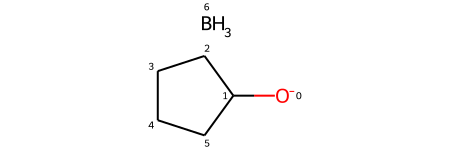

In [160]:
# within a chain

#for bond in aza_canion.GetAtomWithIdx(a_lost[0]).GetBonds():
    #if bond.GetIdx() in c_bonds_made:
        #print("draw atom to bond arrow")
'''curly arrow dictionary

1 : atom to bond
2 : bond to atom

'''
#s1 = Chem.AddHs(cat_and_brom)
#s2 = Chem.AddHs(tert_brom)
#s1 = cat_and_brom  
#s2 = tert_brom

s1 = bh4_red_sm
s2 = bh4_red_prod
mapping = atom_map(s1, s2)

arrows = []

trial = s1

target = Chem.MolToSmiles(s2, isomericSmiles = False)
while Chem.MolToSmiles(s1, isomericSmiles = False) != target:
    Chem.Draw.MolToFile(s1,'inter2.png', addAtomIndices =True)
    no_source = False
    #mapping = atom_map(s1, s2)
    #print(mapping)
    #mapping = {4: 2, 5: 5, 0: 4, 1: 3, 2: 1, 3: 0}
    a_lost, a_gain = find_charge_diff(s1, s2, mapping)
    print(a_lost)
    c_bonds_made, c_bonds_broken = find_bond_diff(s1, s2, mapping)
    chain = set([])
    for bond in c_bonds_made + c_bonds_broken:
        for atom in bond:
            chain.add(atom)
    print(chain)
    #mol_h = Chem.rdmolops.AddHs(s1)
    mol_h = s1
    if len(a_lost)>0:
        a1 = a_lost[0]
    else:
        no_source= True
    #print(a1)
    bond_make = False
    bond_break = False
    for bond in c_bonds_made:
        if no_source:
            a1 = bond[0]
            a2 = bond[1]
            break
        q1 = bond[0]
        q2 = bond[1]
        if q1 == a1:
            a1 = q1
            a2 = q2
            bond_make = True
        elif q2 == a1:
            a1 = q2
            a2 = q1
            bond_make = True
    print(c_bonds_broken)
    for bond in c_bonds_broken:
        q1 = bond[0]
        q2 = bond[1]
        if q1 == a1:
            a1 = q1
            a2 = q2
            bond_break = True
        elif q2 == a1:
            a1 = q2
            a2 = q1
            bond_break = True

    #print(chain)
    print(a1)
    print(a2)
    chain.remove(a1)
    chain.remove(a2)
    if bond_make:
        trial = a_to_b(mol_h,a1,a2)
        arrows.append([1,a1,a2])
    elif bond_break:
        trial = b_to_a(mol_h,a1,a2)
        arrows.append([2,a1,a2])
    Chem.Draw.MolToFile(trial,'debug.png', kekulize=False)
    #Chem.Draw.MolToImage(trial)
    detect_prob = Chem.DetectChemistryProblems(trial)
    if detect_prob:
        p = detect_prob[0]
        counter = 1
    else:
        s1 = trial
        print(Chem.MolToSmiles(s1, isomericSmiles = False))
        continue
    while p.GetType() == "AtomValenceException" and counter < 10:
        i = p.GetAtomIdx()
        for b in trial.GetAtomWithIdx(i).GetBonds():
            j = b.GetOtherAtomIdx(i)
            pair = [i , j]
            pair.sort()
            if pair in c_bonds_broken:
                trial = b_to_a(trial,i,j)
                arrows.append([2,i,j])
                break
        if not Chem.DetectChemistryProblems(trial):
            Chem.Draw.MolToFile(s1,'inter.png')
            s1 = trial
            break
        p = Chem.DetectChemistryProblems(trial)[0]
        counter += 1
    
        #break

trial = Chem.rdmolops.RemoveHs(trial)
Chem.Draw.MolToImage(trial)
    #except valency error:
    #break multiple bonds
print(arrows)
trial

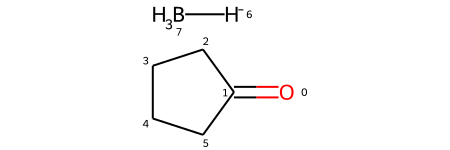

In [159]:
IPythonConsole.drawOptions.addAtomIndices = True
bh4_red_sm

In [154]:
mapping = atom_map(bh4_red_sm, bh4_red_prod)
#print(mapping)
#a_hl = find_charge_diff(s1, s2, mapping)
#b_hl = find_bond_diff(s1, s2, mapping)
#chain = list(find_chain(canion, enolate))
#print(chain)
#Chem.Draw.MolToImage(aza_canion, highlightAtoms=chain, addAtomIndices=True)
s1
print(mapping)

Some weights of the model checkpoint at /scratch/rd611/.conda/envs/rxnmapper/lib/python3.6/site-packages/rxnmapper/models/transformers/albert_heads_8_uspto_all_1310k were not used when initializing AlbertModel: ['predictions.dense.bias', 'predictions.bias', 'predictions.dense.weight', 'predictions.LayerNorm.bias', 'predictions.LayerNorm.weight', 'predictions.decoder.bias', 'predictions.decoder.weight']
- This IS expected if you are initializing AlbertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing AlbertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


[O:4]=[C:3]1[CH2:5][CH2:6][CH2:7][CH2:8]1.[H:2][BH3-:1]>>[BH3:1].[H:2][C:3]1([O-:4])[CH2:5][CH2:6][CH2:7][CH2:8]1
{7: 0, 6: 1, 1: 2, 0: 3, 2: 4, 3: 5, 4: 6, 5: 7}


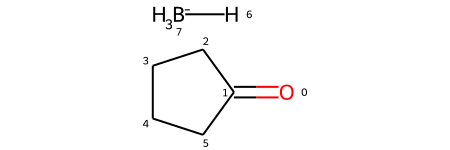

In [155]:
bh4_red_sm

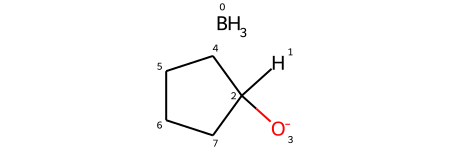

In [156]:
bh4_red_prod

In [ ]:
mapping = atom_map(s1, s2)
a_lost, a_gain = find_charge_diff(s1, s2, mapping)
c_bonds_made, c_bonds_broken = find_bond_diff(s1, s2, mapping)
chain = set([])
for bond in c_bonds_made + c_bonds_broken:
    for atom in bond:
        chain.add(atom)
print(chain)
print(a_lost)
#print(a_gain)
print(c_bonds_broken)
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True
s1
#Chem.Draw.MolToImage(canion)

NameError: name 's1' is not defined